در این مرحله، داده‌های ساعتی بیت‌کوین در برابر تتر را بارگذاری می‌کنیم، نام ستون‌ها را یکدست می‌کنیم و ستون‌های موردنیاز برای ساخت ورودی‌های مدل را نگه می‌داریم. در پایان، داده‌ها را بر اساس زمان مرتب می‌کنیم تا ترتیب کندل‌ها حفظ شود و بتوانیم از اطلاعات گذشته برای پیش‌بینی کندل بعدی استفاده کنیم.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ta.momentum import RSIIndicator
from ta.trend import MACD
from ta.volatility import BollingerBands, AverageTrueRange


In [4]:
df = pd.read_csv("btc_daily.csv")
df.columns = df.columns.str.lower()
df["time"] = pd.to_datetime(df["time"])
df = df[["time", "open", "high", "low", "close", "volume"]]
df = df.sort_values("time").reset_index(drop=True)


In [6]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())


(10866, 6)
time      datetime64[us, UTC+03:30]
open                        float64
high                        float64
low                         float64
close                       float64
volume                      float64
dtype: object
time      0
open      0
high      0
low       0
close     0
volume    0
dtype: int64



در این مرحله، ورودی‌های موردنیاز مدل را از قیمت‌ها و حجم معاملات می‌سازیم. چون قیمت خام در طول زمان تغییر زیادی دارد، از بازده و نسبت‌های قیمتی هم استفاده می‌کنیم. همچنین چند شاخص رایج را محاسبه می‌کنیم که هرکدام بخشی از رفتار بازار را نشان می‌دهند. شاخص قدرت نسبی (آر اس آی) وضعیت حرکت اخیر قیمت را نشان می‌دهد، مک دی برای بررسی روند و حرکت قیمت به کار می‌رود، باندهای بولینگر محدوده تغییرات اخیر قیمت را مشخص می‌کنند و میانگین دامنه واقعی میزان نوسان را اندازه می‌گیرد. همه این مقادیر فقط با استفاده از کندل فعلی و کندل‌های قبل از آن محاسبه می‌شوند.

در ادامه، متغیر هدف را می‌سازیم. اگر قیمت پایانی کندل بعدی بیشتر از قیمت پایانی کندل فعلی باشد، مقدار آن یک و در غیر این صورت صفر خواهد بود. برای آخرین سطر نمی‌توان این مقدار را مشخص کرد، چون قیمت کندل بعدی در داده‌ها وجود ندارد بنابراین این سطر در مرحله بعد حذف می‌شود.

In [7]:
data = df.copy()
data["return_1"] = data["close"].pct_change()
data["return_2"] = data["close"].pct_change(2)
data["return_3"] = data["close"].pct_change(3)
data["return_6"] = data["close"].pct_change(6)
data["candle_range"] = (data["high"] - data["low"]) / data["close"]
data["close_open"] = (data["close"] - data["open"]) / data["open"]
data["volume_change"] = data["volume"].pct_change()
data["rsi_14"] = RSIIndicator(close=data["close"], window=14).rsi()
macd = MACD(close=data["close"], window_slow=26, window_fast=12, window_sign=9)
data["macd"] = macd.macd()
data["macd_signal"] = macd.macd_signal()
data["macd_diff"] = macd.macd_diff()
bollinger = BollingerBands(close=data["close"], window=20, window_dev=2)
data["bb_width"] = bollinger.bollinger_wband()
data["bb_position"] = bollinger.bollinger_pband()
atr = AverageTrueRange(high=data["high"], low=data["low"], close=data["close"], window=14)
data["atr_14"] = atr.average_true_range() / data["close"]
data["target"] = (data["close"].shift(-1) > data["close"]).astype(int)
data.head(10)


,time,open,high,low,close,volume,return_1,return_2,return_3,return_6,...,close_open,volume_change,rsi_14,macd,macd_signal,macd_diff,bb_width,bb_position,atr_14,target
0,2025-07-28 01:30:00+03:30,119265.75,119766.65,119228.56,119495.17,773.18425,NaN,NaN,NaN,NaN,...,0.001924,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0
1,2025-07-28 02:30:00+03:30,119495.16,119528.47,119119.53,119415.55,375.89279,-0.000666,NaN,NaN,NaN,...,-0.000666,-0.513838,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0
2,2025-07-28 03:30:00+03:30,119415.56,119690.32,119126.09,119236.72,466.02933,-0.001498,-0.002163,NaN,NaN,...,-0.001498,0.239793,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0
3,2025-07-28 04:30:00+03:30,119236.72,119480.00,118960.50,119037.77,475.77219,-0.001669,-0.003164,-0.003828,NaN,...,-0.001669,0.020906,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1
4,2025-07-28 05:30:00+03:30,119037.77,119800.00,119021.11,119434.14,578.13763,0.003330,0.001656,0.000156,NaN,...,0.003330,0.215156,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0
5,2025-07-28 06:30:00+03:30,119434.14,119521.03,119234.37,119287.99,304.59253,-0.001224,0.002102,0.000430,NaN,...,-0.001224,-0.473149,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0
6,2025-07-28 07:30:00+03:30,119287.99,119423.58,119128.46,119218.05,341.10705,-0.000586,-0.001809,0.001514,-0.002319,...,-0.000586,0.119880,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1
7,2025-07-28 08:30:00+03:30,119218.06,119701.07,119138.24,119526.13,787.56270,0.002584,0.001996,0.000770,0.000926,...,0.002584,1.308843,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0
8,2025-07-28 09:30:00+03:30,119526.13,119600.00,119440.00,119448.02,349.57844,-0.000653,0.001929,0.001342,0.001772,...,-0.000653,-0.556126,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0
9,2025-07-28 10:30:00+03:30,119448.03,119448.03,118774.31,118900.00,881.81401,-0.004588,-0.005238,-0.002668,-0.001157,...,-0.004588,1.522507,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1



در ابتدای داده‌ها، به‌دلیل محاسبه شاخص‌ها و تغییرات درصدی، بعضی از مقدارها خالی می‌مانند. از طرف دیگر، برای آخرین کندل هم نتیجه روز بعد مشخص نیست. در این مرحله، سطرهایی را که اطلاعات موردنیاز را ندارند حذف می‌کنیم و سپس تعداد و درصد هر دو دسته صعودی و نزولی را بررسی می‌کنیم تا مشخص شود توزیع داده‌ها بین این دو دسته چگونه است.

In [10]:
feature_columns = ["return_1", "return_2", "return_3", "return_6", "candle_range", "close_open", "volume_change",
    "rsi_14", "macd", "macd_signal", "macd_diff", "bb_width", "bb_position", "atr_14"
]

model_data = data.dropna(subset=feature_columns + ["target"]).copy()
model_data = model_data.replace([np.inf, -np.inf], np.nan)
model_data = model_data.dropna(subset=feature_columns + ["target"])
model_data["target"] = model_data["target"].astype(int)
print(model_data["target"].value_counts().sort_index())

target
0    5422
1    5411
Name: count, dtype: int64


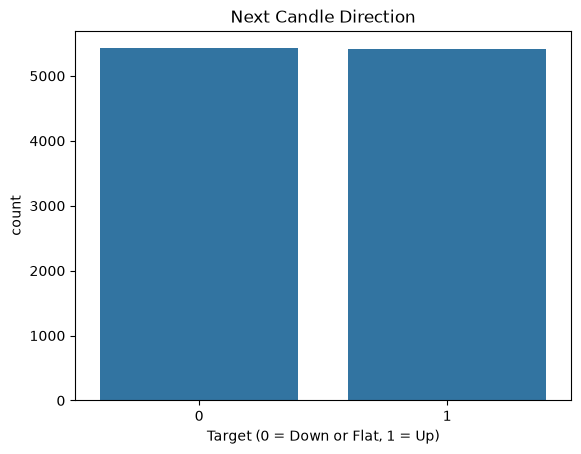

In [11]:
sns.countplot(data=model_data, x="target")
plt.title("Next Candle Direction")
plt.xlabel("Target (0 = Down or Flat, 1 = Up)")
plt.show()


در این مرحله، داده‌ها را بر اساس ترتیب زمانی به دو بخش تقسیم می‌کنیم. هشتاد درصد ابتدایی داده‌ها برای آموزش مدل استفاده می‌شود و بیست درصد پایانی را برای آزمون کنار می‌گذاریم.

In [12]:
split_index = int(len(model_data) * 0.8)
train_data = model_data.iloc[:split_index].copy()
test_data = model_data.iloc[split_index:].copy()

print("rain rows:", len(train_data))
print("Test rows:", len(test_data))
print("Train period:", train_data["time"].min(), "to", train_data["time"].max())
print("Test period:", test_data["time"].min(), "to", test_data["time"].max())


rain rows: 8666
Test rows: 2167
Train period: 2025-07-29 10:30:00+03:30 to 2026-07-25 11:30:00+03:30
Test period: 2026-07-25 12:30:00+03:30 to 2026-10-23 18:30:00+03:30


در این مرحله، ویژگی‌های عددی را هم‌مقیاس می‌کنیم، چون مقدارهای آن‌ها در بازه‌های متفاوتی قرار دارند. برای این کار، از روش کمینه و بیشینه استفاده می‌کنیم و مقادیر کمینه و بیشینه را فقط از داده‌های آموزش به دست می‌آوریم. سپس با استفاده از همین مقادیر، هم داده‌های آموزش و هم داده‌های آزمون را تبدیل می‌کنیم تا اطلاعات داده‌های آزمون بر فرایند تبدیل داده‌های آموزش تأثیری نداشته باشد. اگر مقادیر داده‌های آزمون خارج از محدوده داده‌های آموزش باشند، ممکن است پس از تبدیل کمتر از صفر یا بیشتر از یک شوند.

In [13]:
train_min = train_data[feature_columns].min()
train_max = train_data[feature_columns].max()
train_range = (train_max - train_min).replace(0, 1)

train_scaled = (train_data[feature_columns] - train_min) / train_range
test_scaled = (test_data[feature_columns] - train_min) / train_range

print(train_scaled.describe().loc[["min", "max"]])
print(test_scaled.describe().loc[["min", "max"]])


     return_1  return_2  return_3  return_6  candle_range  close_open  \
min       0.0       0.0       0.0       0.0           0.0         0.0   
max       1.0       1.0       1.0       1.0           1.0         1.0   

     volume_change  rsi_14  macd  macd_signal  macd_diff  bb_width  \
min            0.0     0.0   0.0          0.0        0.0       0.0   
max            1.0     1.0   1.0          1.0        1.0       1.0   

     bb_position  atr_14  
min          0.0     0.0  
max          1.0     1.0  
     return_1  return_2  return_3  return_6  candle_range  close_open  \
min  0.318570  0.247991  0.255602  0.361988     -0.001321    0.318571   
max  1.062424  0.981845  0.965096  1.020014      0.453561    1.062426   

     volume_change    rsi_14      macd  macd_signal  macd_diff  bb_width  \
min       0.001846  0.127643  0.472656     0.472118   0.262388 -0.001464   
max       0.599351  1.025602  1.108788     1.096833   0.758416  0.726016   

     bb_position    atr_14  
min     0.

در این مرحله، مجموعه‌داده‌های نهایی را آماده و بررسی می‌کنیم. ستون‌های زمان و قیمت پایانی را نگه می‌داریم تا بتوانیم هر مشاهده را دنبال کنیم و نتایج را بهتر تفسیر کنیم، اما از آن‌ها به‌عنوان ورودی مدل استفاده نمی‌کنیم. متغیر هدف نیز جدا از ستون‌های ویژگی نگهداری می‌شود. در پایان، ابعاد مجموعه‌داده‌ها، مقادیر خالی، سطرهای تکراری و حفظ ترتیب زمانی را بررسی می‌کنیم تا از آماده بودن داده‌ها برای آموزش و ارزیابی مدل مطمئن شویم.

In [14]:
train_prepared = train_scaled.copy()
train_prepared["time"] = train_data["time"].values
train_prepared["close"] = train_data["close"].values
train_prepared["target"] = train_data["target"].values

test_prepared = test_scaled.copy()
test_prepared["time"] = test_data["time"].values
test_prepared["close"] = test_data["close"].values
test_prepared["target"] = test_data["target"].values

prepared_data = pd.concat([train_prepared, test_prepared], ignore_index=True)
prepared_data = prepared_data[["time", "close"] + feature_columns + ["target"]]

print(prepared_data.shape)
print(prepared_data.isnull().sum())
print(prepared_data.duplicated().sum())
print(prepared_data["time"].is_monotonic_increasing)
prepared_data.head()


(10833, 17)
time             0
close            0
return_1         0
return_2         0
return_3         0
return_6         0
candle_range     0
close_open       0
volume_change    0
rsi_14           0
macd             0
macd_signal      0
macd_diff        0
bb_width         0
bb_position      0
atr_14           0
target           0
dtype: int64
0
True


,time,close,return_1,return_2,return_3,return_6,candle_range,close_open,volume_change,rsi_14,macd,macd_signal,macd_diff,bb_width,bb_position,atr_14,target
0,2025-07-29 07:00:00,118882.37,0.593308,0.470617,0.535382,0.633099,0.034851,0.593308,0.100343,0.581507,0.620599,0.568320,0.570694,0.061977,0.715236,0.104591,1
1,2025-07-29 08:00:00,118923.80,0.585581,0.476747,0.520185,0.616335,0.017586,0.585582,0.015682,0.590163,0.630588,0.578878,0.572024,0.063230,0.723561,0.099456,0
2,2025-07-29 09:00:00,118784.79,0.567290,0.456225,0.513184,0.568458,0.013217,0.567290,0.084105,0.550715,0.635665,0.588460,0.563299,0.066269,0.667912,0.093508,0
3,2025-07-29 10:00:00,118317.75,0.533985,0.415590,0.473800,0.554528,0.035438,0.533985,0.122043,0.437895,0.630281,0.594922,0.535473,0.065396,0.522044,0.095535,1
4,2025-07-29 11:00:00,118592.38,0.609359,0.448631,0.489519,0.555060,0.028285,0.609362,0.052754,0.502734,0.631583,0.600382,0.526536,0.066393,0.598332,0.094212,1


در این مرحله، مجموعه‌داده کامل آماده‌شده و همچنین فایل‌های جداگانه آموزش و آزمون را با حفظ ترتیب زمانی ذخیره می‌کنیم. در مرحله مدل‌سازی، فقط از ستون‌های ویژگی برای ورودی مدل استفاده می‌کنیم. ستون‌های زمان، قیمت پایانی و متغیر هدف را وارد ماتریس ورودی نمی‌کنیم تا مدل فقط بر اساس ویژگی‌های تعیین‌شده آموزش ببیند.

In [15]:
prepared_data.to_csv("btc_prepared.csv", index=False)
train_prepared.to_csv("btc_train.csv", index=False)
test_prepared.to_csv("btc_test.csv", index=False) 

تا اینجا ویژگی‌های مربوط به بازده، کندل‌ها، حجم معاملات و شاخص‌های فنی را ایجاد کردیم و جهت حرکت کندل بعدی را به‌عنوان متغیر هدف تعریف کردیم. سپس سطرهای دارای مقادیر ناقص را حذف کردیم، داده‌ها را بر اساس ترتیب زمانی به مجموعه‌های آموزش و آزمون تقسیم کردیم و ویژگی‌ها را با استفاده از اطلاعات مجموعه آموزش هم‌مقیاس کردیم. خروجی اصلی، فایل btc_prepared.csv است. همچنین فایل‌های جداگانه آموزش و آزمون برای استفاده در مرحله مدل‌سازی ذخیره شده‌اند.